# Home Loan Approval Prediction

## Project Overview

This project develops a machine learning classification workflow to predict whether a home loan application will be approved based on applicant financial, demographic, credit, and property-related information.

The project includes data exploration, data cleaning, exploratory data analysis, preprocessing, feature selection, model training, hyperparameter tuning, and model evaluation.

## Business Problem

Loan approval is an important decision for financial institutions and typically involves evaluating multiple applicant, financial, credit, and property-related characteristics.

The objective of this project is to develop a machine learning classification model that can identify patterns associated with historical loan approval decisions and predict whether an application is likely to be classified as approved or rejected.

The project focuses on predictive performance rather than estimating borrower default risk, since the dataset contains historical approval status rather than loan repayment outcomes.

## Target Variable

The target variable is:

`Loan_Status`

where:

- `1` represents an approved loan.
- `0` represents a rejected loan.

## Evaluation Considerations

Because the target classes are not perfectly balanced, model performance should not be evaluated using accuracy alone.

Metrics such as **Precision, Recall, F1-score, ROC-AUC, and the Confusion Matrix** will be considered when comparing classification models.

Particular attention will be given to false positive predictions, where the model predicts loan approval for an application whose actual status is not approved.

# Importing Libraries

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
sns.set_theme(style='whitegrid')

# Data Loading and Overview

In [40]:
df = pd.read_csv('loan_sanction_train.csv')
print("Dataset shape: ",df.shape)
df.head()

Dataset shape:  (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


In [42]:
# Checking for duplicates
print("Number of duplicates: ",df.duplicated().sum())

# Checking for missing values
missing_values = pd.DataFrame({
    'Missing Values' : df.isna().sum(),
    'Percentage(%)' : ((df.isna().mean()*100).round(2))
})

missing_values[missing_values['Missing Values']>0]

Number of duplicates:  0


,Missing Values,Percentage(%)
Gender,13,2.12
Married,3,0.49
Dependents,15,2.44
Self_Employed,32,5.21
LoanAmount,22,3.58
Loan_Amount_Term,14,2.28
Credit_History,50,8.14


### Initial Data Quality Findings

- No duplicate observations were found.
- Several features contain missing values and will require appropriate handling during preprocessing.
- Missing-value imputation will be included inside the preprocessing pipeline to reduce the risk of data leakage.

In [43]:
df.select_dtypes('object').nunique()

C:\Users\hp\AppData\Local\Temp\ipykernel_15256\3198987469.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes('object').nunique()


Loan_ID          614
Gender             2
Married            2
Dependents         4
Education          2
Self_Employed      2
Property_Area      3
Loan_Status        2
dtype: int64

### Identifier Feature

`Loan_ID` is a unique identifier for each loan application. Since it does not represent a meaningful predictive characteristic of the applicant, it is excluded from the modeling features.

In [44]:
df.drop(columns = ['Loan_ID'],inplace = True)


In [45]:
df.select_dtypes('number').nunique()

ApplicantIncome      505
CoapplicantIncome    287
LoanAmount           203
Loan_Amount_Term      10
Credit_History         2
dtype: int64

### Feature Type Considerations

`Credit_History` is treated as a categorical feature because its values represent two distinct categories rather than a continuous numerical quantity.

Although `Loan_Amount_Term` has relatively low cardinality, it represents the loan duration in months. Therefore, it is retained as a numerical feature so that the ordering and magnitude of the loan term are preserved.

In [46]:
print("Loan_Amount_Term Value counts:\n",df['Loan_Amount_Term'].value_counts())
print("\nCredit_History Value counts:\n",df['Credit_History'].value_counts())

Loan_Amount_Term Value counts:
 Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64

Credit_History Value counts:
 Credit_History
1.0    475
0.0     89
Name: count, dtype: int64


In [47]:
# Mapping target values
df['Loan_Status'] = df['Loan_Status'].map({'Y': 1, 'N': 0})

# Converting Credit History to a categorical variable
df['Credit_History'] = df['Credit_History'].map({1: 'Yes', 0: 'No'})

In [48]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Loan_Status
count,614.000000,614.000000,592.000000,600.00000,614.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.687296
std,6109.041673,2926.248369,85.587325,65.12041,0.463973
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,0.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [49]:
df.describe(include='object')

C:\Users\hp\AppData\Local\Temp\ipykernel_15256\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Gender,Married,Dependents,Education,Self_Employed,Credit_History,Property_Area
count,601,611,599,614,582,564,614
unique,2,2,4,2,2,2,3
top,Male,Yes,0,Graduate,No,Yes,Semiurban
freq,489,398,345,480,500,475,233


### Numerical Feature Observations

- `ApplicantIncome`, `CoapplicantIncome`, and `LoanAmount` show right-skewed distributions and contain relatively large values.
- `CoapplicantIncome` contains a substantial number of zero values.
- Potential outliers will be investigated visually before deciding whether any transformation or filtering is appropriate.

# Univariate Analysis

C:\Users\hp\AppData\Local\Temp\ipykernel_15256\87256667.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = df.select_dtypes('object').columns


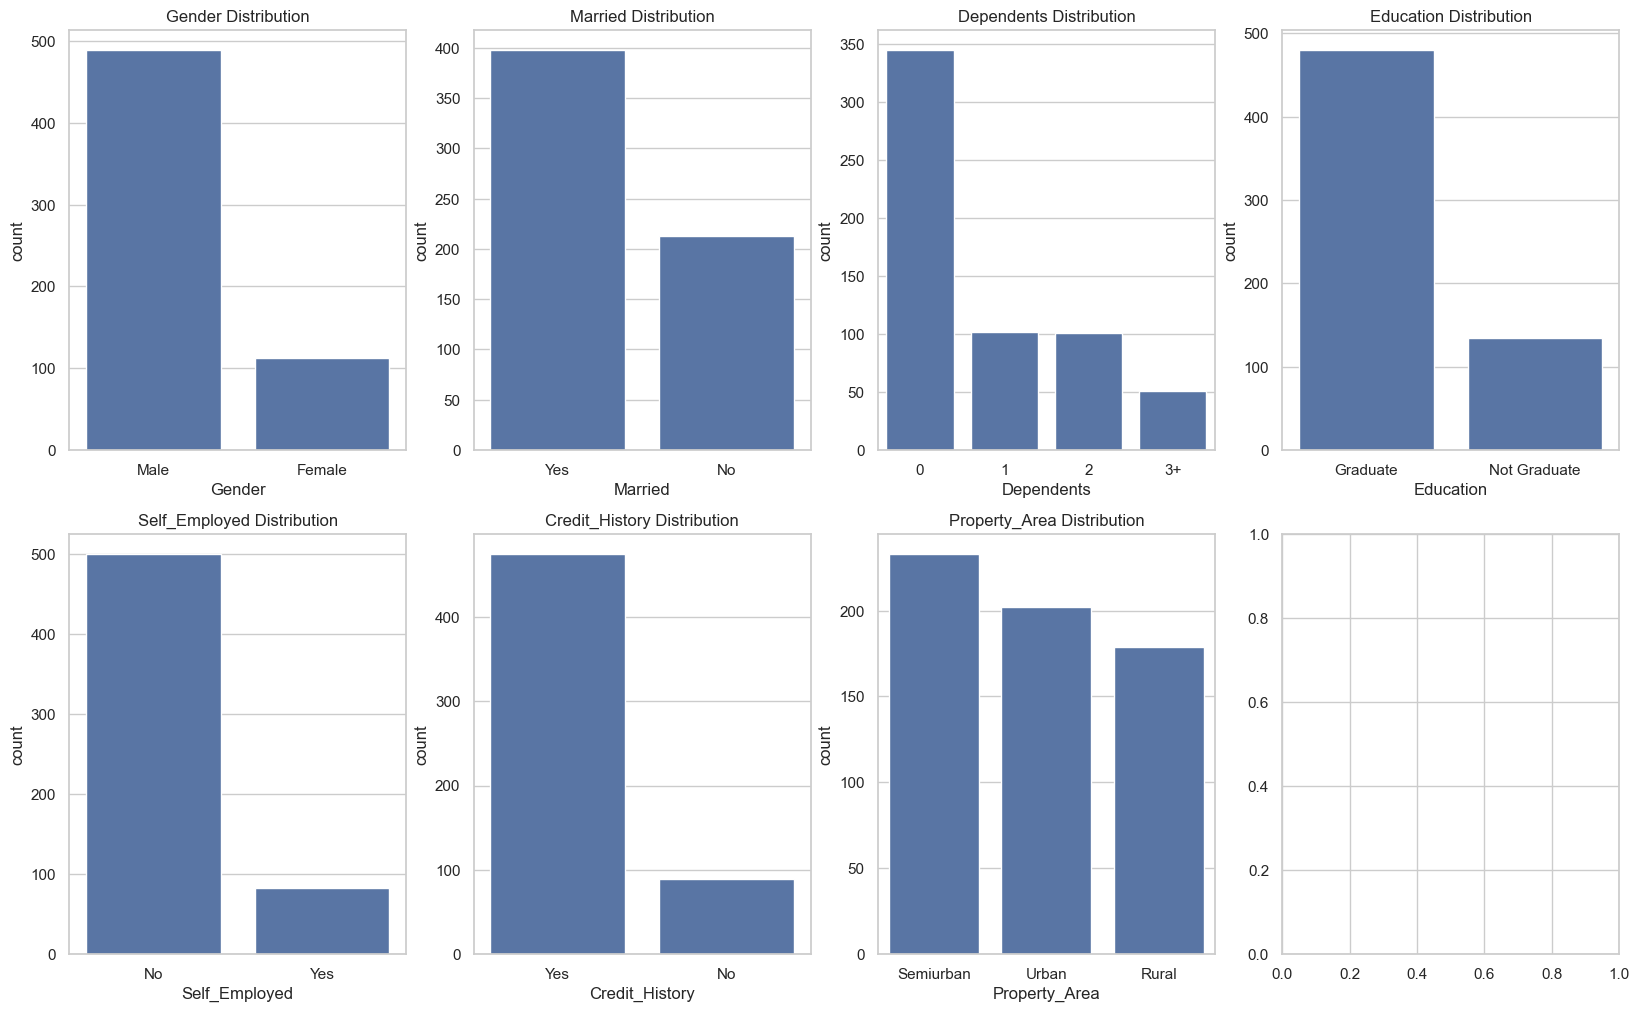

In [50]:
cat_features = df.select_dtypes('object').columns
fig,ax = plt.subplots(2,4,figsize=(20,12))

for i,feature in enumerate(cat_features):
    order = (
        df[feature]
        .value_counts(normalize = True )
        .sort_values(ascending=False).index 
    )
    sns.countplot(data=df,x=feature,ax=ax[i//4,i%4],order = order)
    ax[i//4,i%4].set_title(f'{feature} Distribution')

### Categorical Feature Observations

- Most applicants in the dataset are male.
- A larger proportion of applicants are married.
- Many applicants report no dependents.
- Graduate applicants represent the majority of observations.
- Most applicants are not self-employed.
- The distribution of property areas varies across Rural, Semiurban, and Urban categories.

These observations describe the applicant composition of this dataset and do not by themselves indicate which features are predictive of loan approval.

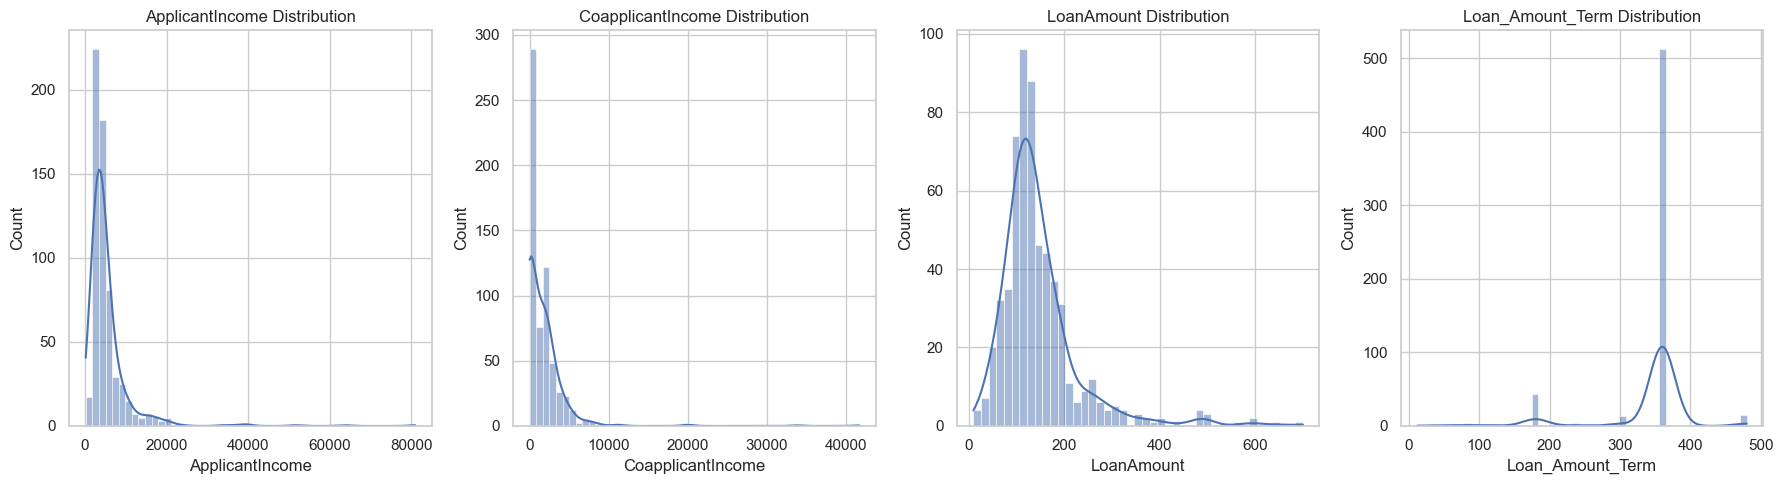

In [51]:
continuous_features = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, feature in enumerate(continuous_features):
    sns.histplot(data=df, x=feature, kde=True, ax=axes[i])
    axes[i].set_title(f'{feature} Distribution')

plt.tight_layout()
plt.show()

### Numerical Distribution Observations

- `ApplicantIncome`, `CoapplicantIncome`, and `LoanAmount` are right-skewed.
- Several relatively large values are visible, particularly for applicant and coapplicant income.
- `CoapplicantIncome` also contains many zero values.
- These distributions will be considered when designing the preprocessing strategy.

## Outlier and Skewness Handling

The numerical feature distributions revealed strong right skewness and several extreme values, particularly in `ApplicantIncome`, `CoapplicantIncome`, and `LoanAmount`.

To reduce the influence of extreme observations:

- Observations with `CoapplicantIncome >= 10000` were removed as part of the experimental preprocessing strategy.
- A `log1p` transformation was applied to `ApplicantIncome` and `LoanAmount` to reduce right skewness while retaining their observations.

These preprocessing decisions were based on the distributions observed during exploratory data analysis and will be documented as part of the modeling workflow.

In [52]:
df = df[df['CoapplicantIncome'] < 10000].copy()

for col in ['LoanAmount', 'ApplicantIncome']:
    df[col] = np.log1p(df[col])

In [53]:
print("Dataset shape after outlier handling:", df.shape)

Dataset shape after outlier handling: (608, 12)


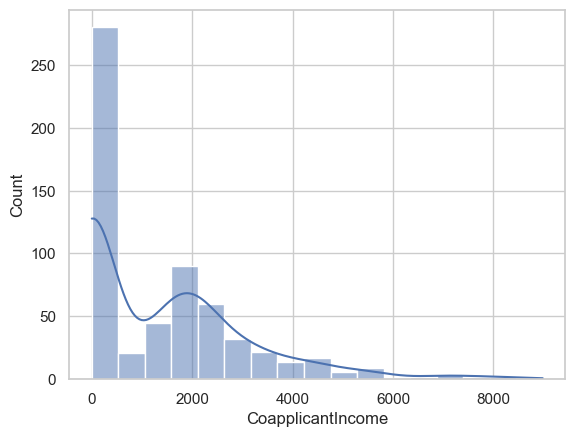

In [54]:
sns.histplot(df['CoapplicantIncome'], kde=True);

## Target Distribution

In [55]:
target_distribution = (df['Loan_Status'].value_counts(normalize=True).sort_index().mul(100).round(2)
)

print(target_distribution)

Loan_Status
0    30.76
1    69.24
Name: proportion, dtype: float64


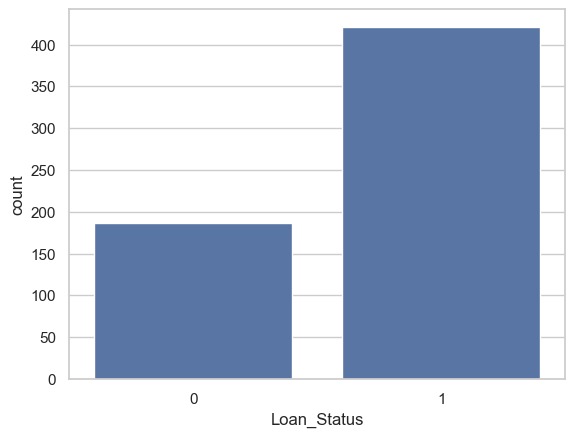

In [56]:
sns.countplot(data=df, x='Loan_Status');

### Target Distribution

The target variable is moderately imbalanced, with approved applications representing a larger proportion of the dataset than rejected applications.

Because of this imbalance, model evaluation will not rely on accuracy alone. Precision, recall, F1-score, ROC-AUC, and the confusion matrix will also be considered.

# Bivariate Analysis

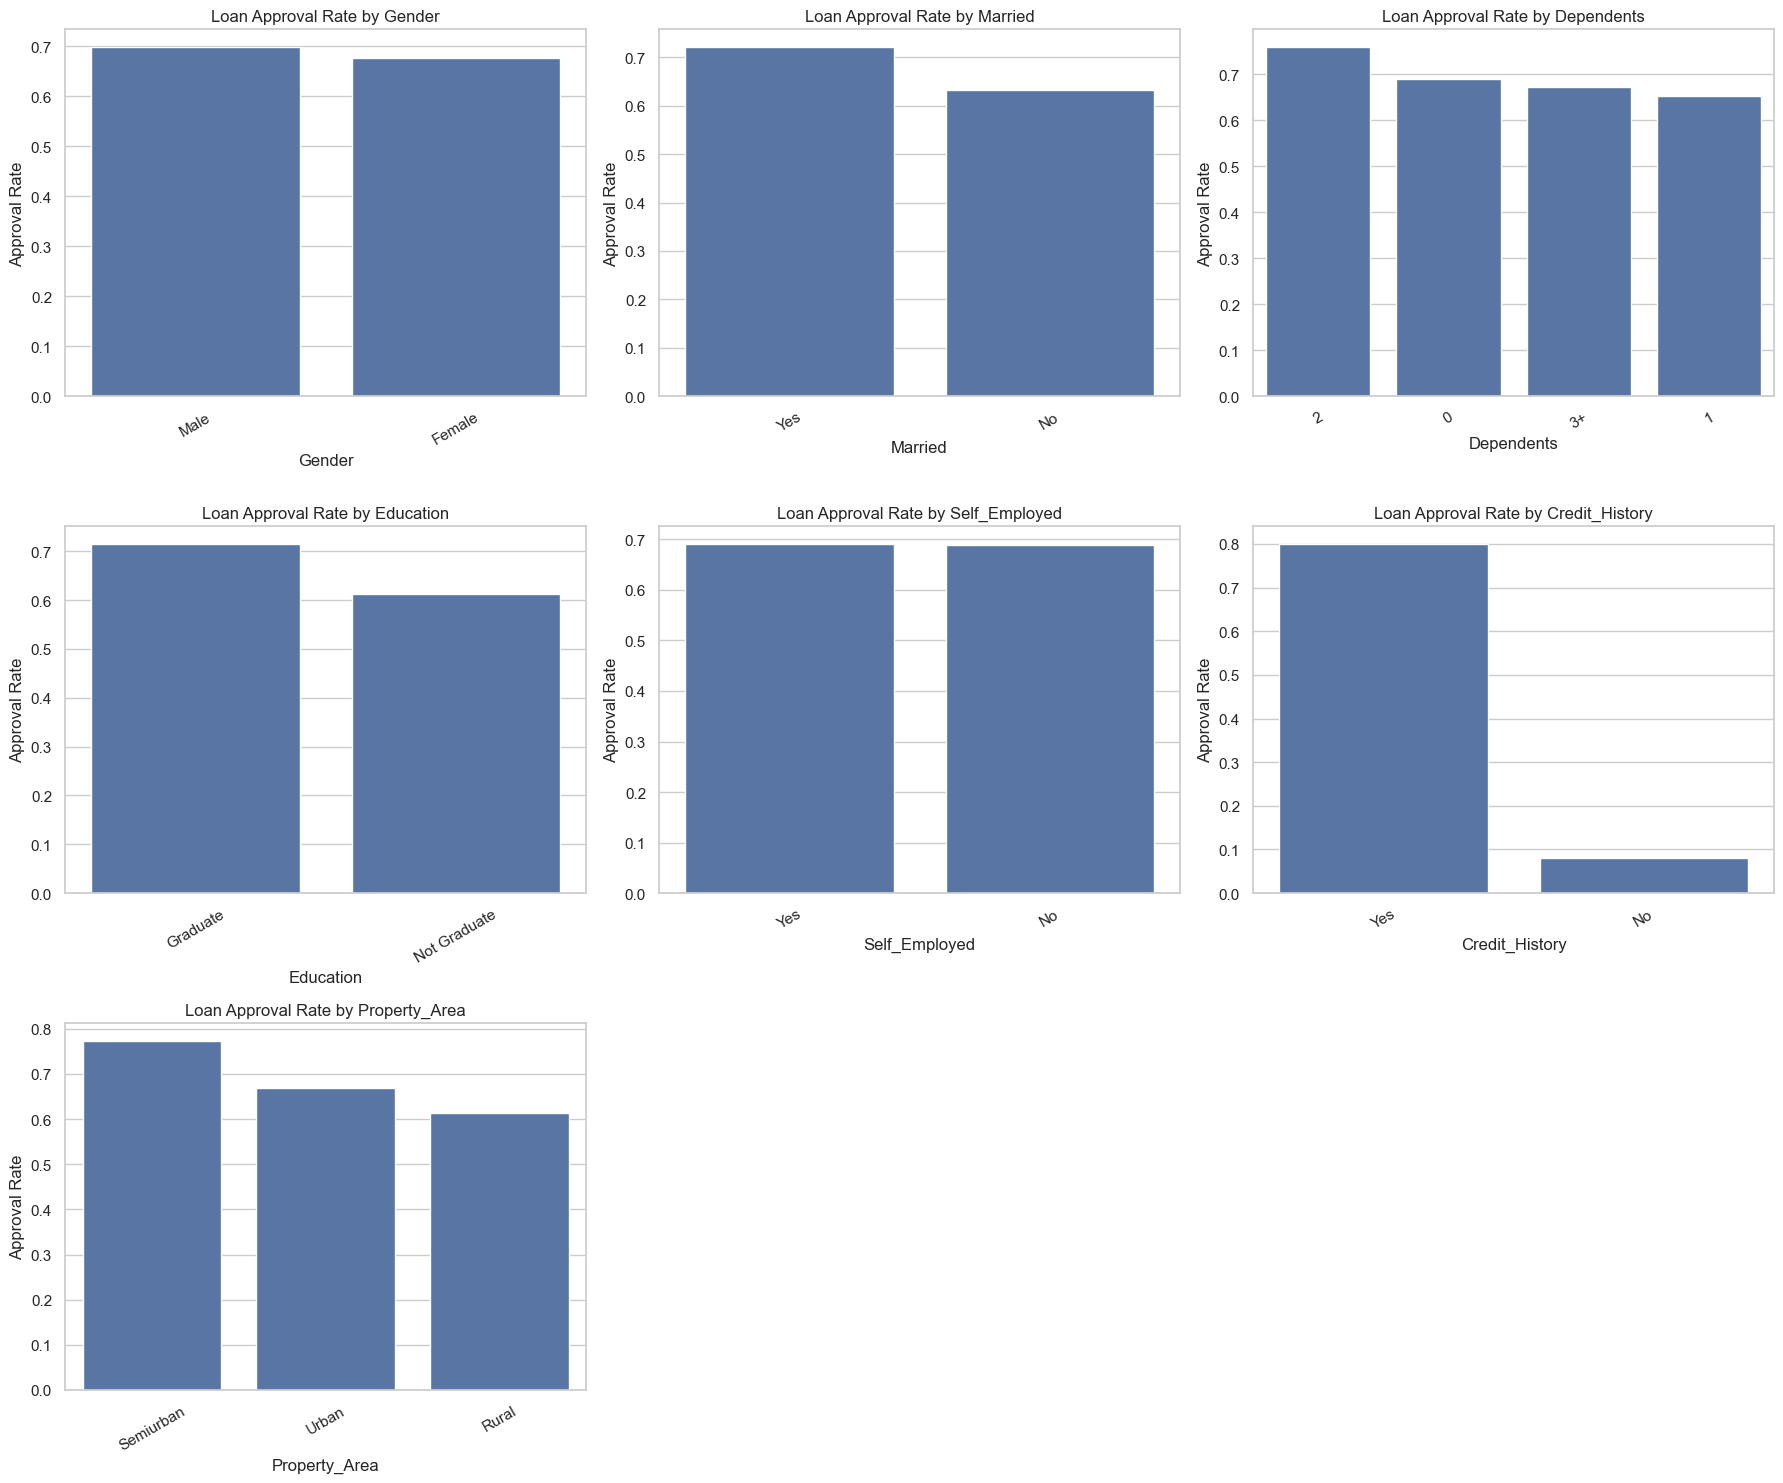

In [57]:
import math

n_cols = 3
n_rows = math.ceil(len(cat_features) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

for i, feature in enumerate(cat_features):

    order = ( df.groupby(feature)['Loan_Status'] .mean() .sort_values(ascending=False) .index)

    sns.barplot( data=df, x=feature, y='Loan_Status', order=order, errorbar=None, ax=axes[i])

    axes[i].set_title(f'Loan Approval Rate by {feature}')
    axes[i].set_ylabel('Approval Rate')
    axes[i].tick_params(axis='x', rotation=30)

# Remove unused plots
for j in range(len(cat_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Categorical Features vs. Loan Approval

The approval-rate plots suggest that loan approval proportions vary across several categorical groups.

These differences represent descriptive associations within the dataset and should not be interpreted as causal relationships or as evidence that a feature is necessarily important for prediction.

Feature usefulness will be assessed later through model performance rather than being determined solely from these visual comparisons.

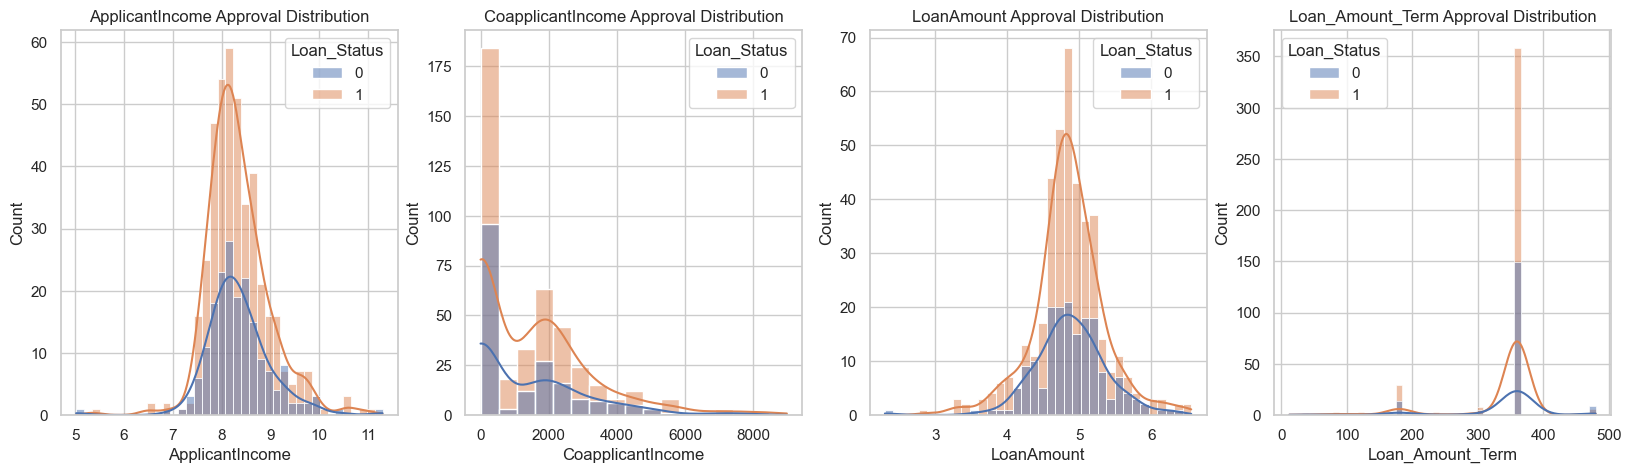

In [58]:
num_features = df.select_dtypes('number').columns.drop('Loan_Status')
fig,ax = plt.subplots(1, 4, figsize=(20,5))

for i,feature in enumerate(num_features):
    sns.histplot(data=df, x=feature, ax=ax[i], kde=True, hue="Loan_Status")
    ax[i].set_title(f'{feature} Approval Distribution')

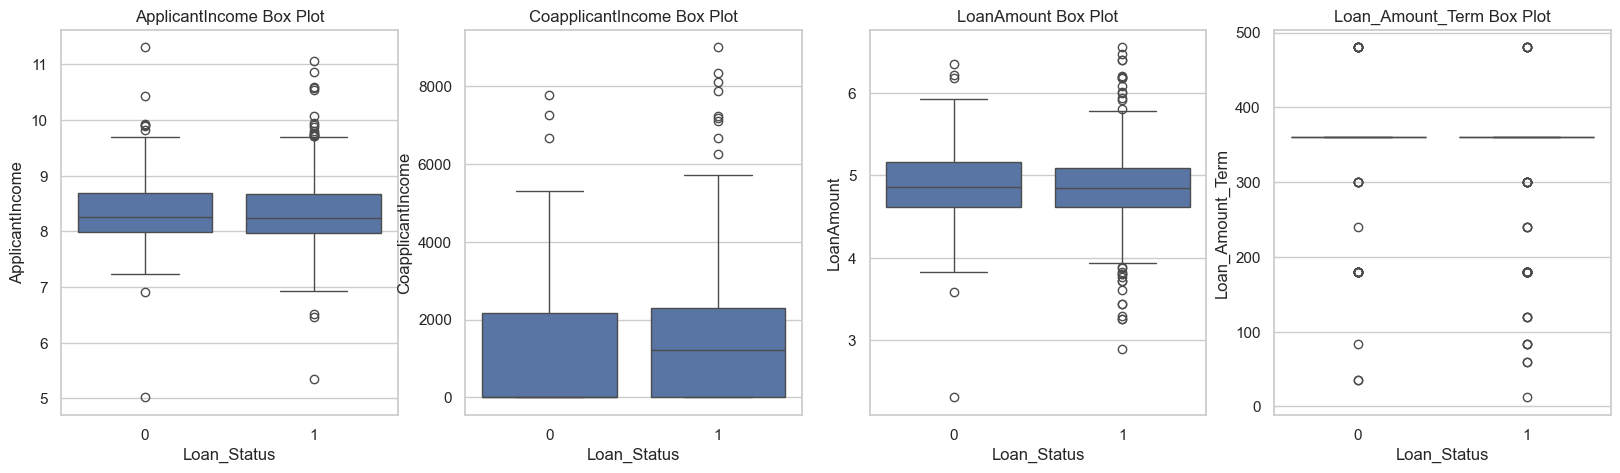

In [59]:
fig,ax = plt.subplots(1,4,figsize=(20,5))

for i,feature in enumerate(num_features):
    sns.boxplot(data=df, x="Loan_Status" ,y=feature,ax=ax[i])
    ax[i].set_title(f'{feature} Box Plot')

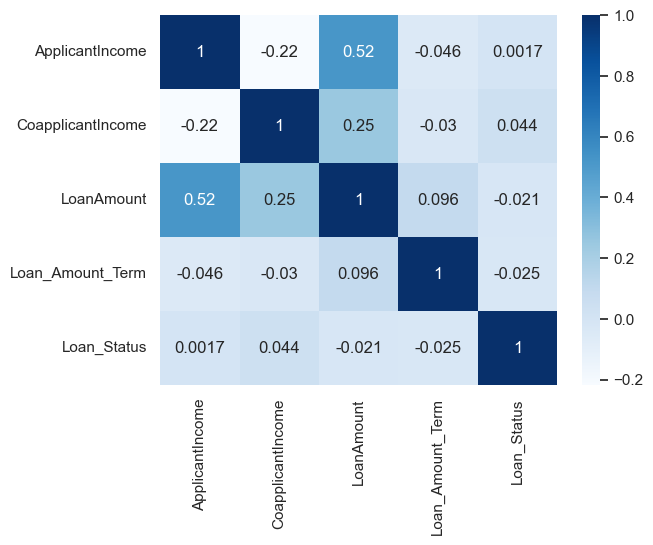

In [60]:
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='Blues');

### Correlation Analysis

The correlation matrix summarizes linear relationships among numerical variables.

Because several predictors are categorical, this matrix provides only a partial view of feature relationships and should not be used alone for feature selection.

# Modeling Preparation

## Feature Selection Considerations

`Loan_ID` was removed because it is a unique identifier and does not provide meaningful applicant information.

The remaining applicant, financial, credit, and property-related features are initially retained for model development. Features are not removed solely because exploratory plots show weak associations with the target, since predictive usefulness may emerge through interactions with other variables.

`Gender` requires additional consideration because it is a sensitive demographic attribute. Model performance can later be compared with and without this feature to evaluate whether excluding it is appropriate for the final modeling objective.

# Import Required Libraries

In [77]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV

from sklearn.preprocessing import  StandardScaler, OneHotEncoder, PolynomialFeatures

from sklearn.impute import SimpleImputer

from sklearn.compose import make_column_transformer

from sklearn.pipeline import  make_pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report, RocCurveDisplay
)


In [62]:
def prediction_report(model, X, y):
    y_pred = model.predict(X)

    print(classification_report(y, y_pred))
    
    ConfusionMatrixDisplay.from_predictions(y, y_pred, cmap='Blues')

    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

In [63]:
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def model_tuning(model, X_train, y_train, params):
    
    grid_search = GridSearchCV(
        estimator=model,
        param_grid=params,
        cv=stratified_cv,
        scoring='f1',
        n_jobs=-1,
        refit=True
    )
    
    grid_search.fit(X_train, y_train)
    
    print("Best parameters:", grid_search.best_params_)
    print(f"Best CV F1-score: {grid_search.best_score_:.4f}")
    
    return grid_search.best_estimator_

# Data Preprocessing

The dataset is prepared for machine learning by separating the target variable from the predictor features.

Preprocessing transformations such as missing-value imputation, categorical encoding, and feature scaling will be fitted only on the training data through a Scikit-learn pipeline to reduce the risk of data leakage.

In [64]:
X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status']

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())
print("\nTarget distribution:")
print(y.value_counts())
print(y.value_counts(normalize=True).round(3))

X shape: (608, 11)
y shape: (608,)


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,Male,No,0,Graduate,No,8.674197,0.0,NaN,360.0,Yes,Urban
1,Male,Yes,1,Graduate,No,8.430327,1508.0,4.859812,360.0,Yes,Rural
2,Male,Yes,0,Graduate,Yes,8.006701,0.0,4.204693,360.0,Yes,Urban
3,Male,Yes,0,Not Graduate,No,7.857094,2358.0,4.795791,360.0,Yes,Urban
4,Male,No,0,Graduate,No,8.699681,0.0,4.955827,360.0,Yes,Urban



Target distribution:
Loan_Status
1    421
0    187
Name: count, dtype: int64
Loan_Status
1    0.692
0    0.308
Name: proportion, dtype: float64


In [65]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [66]:
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.20, random_state=42, stratify=y_train_val)

In [67]:
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

print("\nTarget proportions:")

print("Train:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation:")
print(y_val.value_counts(normalize=True).round(3))

print("\nTest:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (388, 11) (388,)
Validation set: (98, 11) (98,)
Test set: (122, 11) (122,)

Target proportions:
Train:
Loan_Status
1    0.693
0    0.307
Name: proportion, dtype: float64

Validation:
Loan_Status
1    0.694
0    0.306
Name: proportion, dtype: float64

Test:
Loan_Status
1    0.689
0    0.311
Name: proportion, dtype: float64


In [68]:
X_train.dtypes

Gender                   str
Married                  str
Dependents               str
Education                str
Self_Employed            str
ApplicantIncome      float64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History           str
Property_Area            str
dtype: object

In [69]:
numerical_features = [ 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']

categorical_features = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Credit_History', 'Property_Area']

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']
Categorical features: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Credit_History', 'Property_Area']


In [70]:
#numerical features pipeline
num_pipeline = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
)
#categorical features pipeline
cat_pipeline = make_pipeline(
    SimpleImputer(strategy = 'most_frequent'),
    OneHotEncoder(handle_unknown='ignore'),
)

# Combine both pipelines
preprocessor = make_column_transformer(
    (num_pipeline, numerical_features),
    (cat_pipeline, categorical_features)
)

## Preprocessing Summary

The data preprocessing workflow is now ready for model development.

- The target variable was separated from the predictor features.
- The data was split into training, validation, and test sets using stratified sampling to preserve the target-class proportions.
- Numerical features are median-imputed and standardized.
- Categorical features are imputed using the most frequent category and one-hot encoded.
- Preprocessing is incorporated into each model pipeline so that transformations are learned from the training data.
- The validation set will be used for model comparison and selection.
- The test set will remain untouched until the final model has been selected.

The next stage evaluates multiple classification algorithms using the same preprocessing and evaluation strategy.

# Modeling

Several classification algorithms will be trained and evaluated using the same preprocessing workflow.

Model development will follow these principles:

- Models are trained using the training set.
- The validation set is used to compare model performance and support model selection.
- Hyperparameter tuning is performed using stratified cross-validation on the training data.
- The test set remains untouched until the final model is selected.

The models are evaluated using Accuracy, Precision, Recall, F1-score, ROC-AUC, and the Confusion Matrix.

## 1. Logistic Regression

Logistic Regression is used as the baseline classification model. The preprocessing steps and the classifier are combined into a single pipeline to ensure that preprocessing is learned only from the training data.

In [126]:
log_reg = make_pipeline(
    preprocessor,
    LogisticRegression
    (
        max_iter=1000,
        random_state=42
    )       
)

In [127]:
log_reg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('pipeline-1', ...), ('pipeline-2', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

              precision    recall  f1-score   support

           0       0.85      0.48      0.61       119
           1       0.81      0.96      0.88       269

    accuracy                           0.81       388
   macro avg       0.83      0.72      0.75       388
weighted avg       0.82      0.81      0.80       388



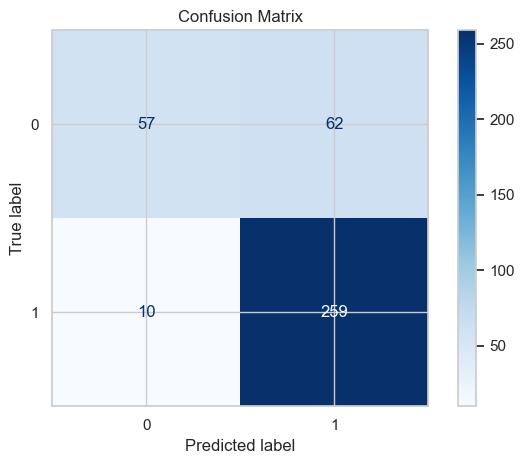

In [128]:
prediction_report(log_reg, X_train, y_train)

              precision    recall  f1-score   support

           0       0.93      0.47      0.62        30
           1       0.81      0.99      0.89        68

    accuracy                           0.83        98
   macro avg       0.87      0.73      0.75        98
weighted avg       0.85      0.83      0.81        98



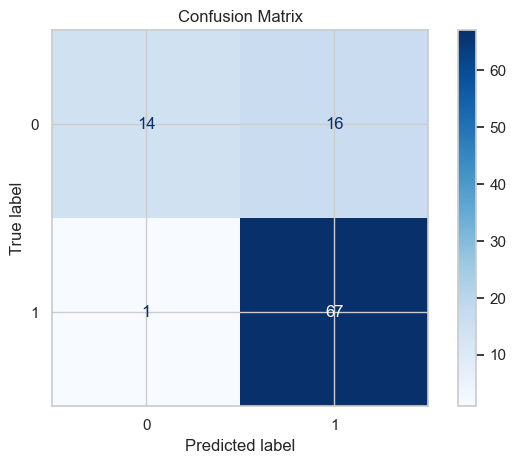

In [129]:
prediction_report(log_reg, X_val, y_val)

In [130]:
y_val_prob = log_reg.predict_proba(X_val)[:, 1]

log_reg_auc = roc_auc_score(y_val, y_val_prob)

print(f"Validation ROC-AUC: {log_reg_auc:.4f}")

Validation ROC-AUC: 0.6843


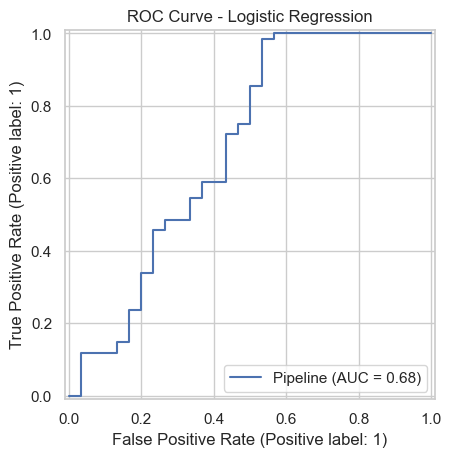

In [131]:
RocCurveDisplay.from_estimator(
    log_reg,
    X_val,
    y_val
)

plt.title('ROC Curve - Logistic Regression')
plt.show()

### Logistic Regression Hyperparameter Tuning

Hyperparameter tuning is performed using `GridSearchCV` with stratified 5-fold cross-validation on the training data.

The regularization strength (`C`) and regularization type (`penalty`) are evaluated. The F1-score is used as the optimization metric during cross-validation.

In [132]:
param_grid = {
    'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'logisticregression__penalty': ['l1', 'l2'],
    'logisticregression__solver': ['liblinear']
}

best_log_reg = model_tuning(
    log_reg,
    X_train,
    y_train,
    param_grid
)

Best parameters: {'logisticregression__C': 0.1, 'logisticregression__penalty': 'l1', 'logisticregression__solver': 'liblinear'}
Best CV F1-score: 0.8820


c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


              precision    recall  f1-score   support

           0       0.93      0.47      0.62        30
           1       0.81      0.99      0.89        68

    accuracy                           0.83        98
   macro avg       0.87      0.73      0.75        98
weighted avg       0.85      0.83      0.81        98



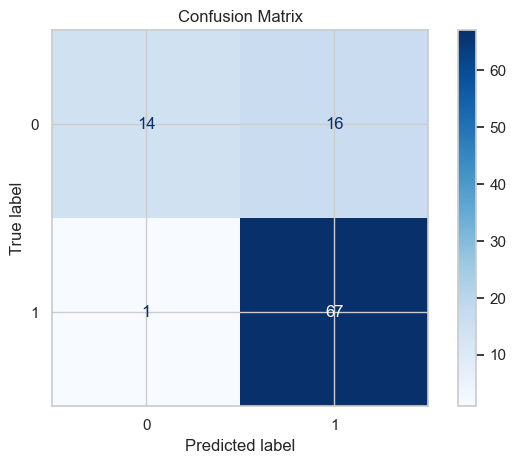

In [133]:
prediction_report(
    best_log_reg,
    X_val,
    y_val
)

In [134]:
y_val_prob_tuned = best_log_reg.predict_proba(X_val)[:, 1]

tuned_log_reg_auc = roc_auc_score(
    y_val,
    y_val_prob_tuned
)

print(f"Tuned Logistic Regression Validation ROC-AUC: {tuned_log_reg_auc:.4f}")

Tuned Logistic Regression Validation ROC-AUC: 0.7309


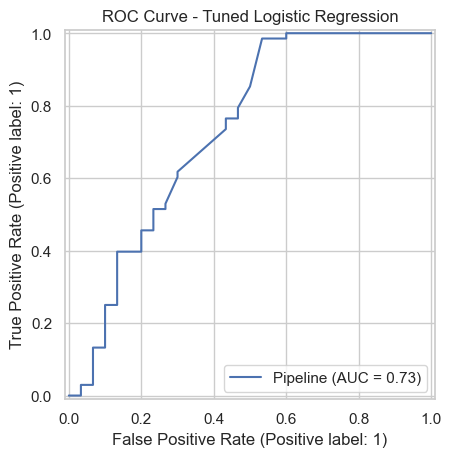

In [135]:
RocCurveDisplay.from_estimator(
    best_log_reg,
    X_val,
    y_val
)

plt.title('ROC Curve - Tuned Logistic Regression')
plt.show()

### Logistic Regression Results

The baseline Logistic Regression model achieved a validation accuracy of 0.83 and showed similar performance on the training and validation sets, indicating no clear evidence of overfitting.

After hyperparameter tuning using stratified 5-fold cross-validation, the best configuration was:

- `C = 0.1`
- `penalty = 'l1'`
- `solver = 'liblinear'`

The tuned model achieved a cross-validation F1-score of 0.8820.

On the validation set, the classification metrics at the default decision threshold remained largely unchanged. However, ROC-AUC improved from approximately 0.68 to 0.7309, indicating better overall discrimination between the two classes.

The model maintained very high recall for approved applications (class 1), while recall for rejected applications (class 0) remained considerably lower. Therefore, class-specific performance will be considered when comparing Logistic Regression with the remaining classification models.

## 2. Support Vector Classifier (SVC)

Support Vector Classifier (SVC) is evaluated as the second classification model.

SVC attempts to identify a decision boundary that maximizes the separation between the two classes. The same preprocessing pipeline is used to ensure consistent preprocessing across models.

A baseline SVC model is first trained using the default hyperparameters before performing hyperparameter tuning.

In [136]:
svc = make_pipeline(
    preprocessor,
    SVC(
        probability=True,
        random_state=42
    )
)

svc.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('pipeline-1', ...), ('pipeline-2', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differen

              precision    recall  f1-score   support

           0       0.97      0.50      0.66       119
           1       0.82      0.99      0.90       269

    accuracy                           0.84       388
   macro avg       0.89      0.74      0.78       388
weighted avg       0.86      0.84      0.82       388



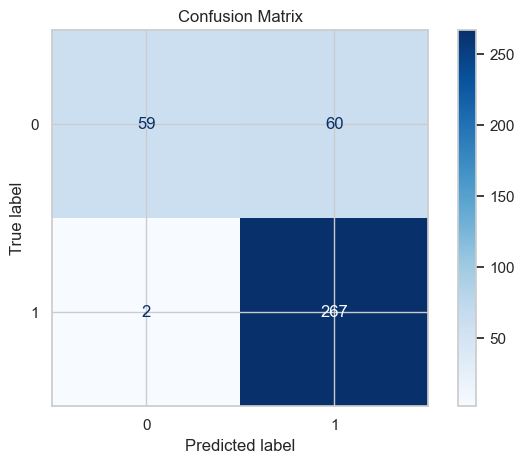

In [137]:
prediction_report(
    svc,
    X_train, 
    y_train
)

              precision    recall  f1-score   support

           0       0.93      0.43      0.59        30
           1       0.80      0.99      0.88        68

    accuracy                           0.82        98
   macro avg       0.86      0.71      0.74        98
weighted avg       0.84      0.82      0.79        98



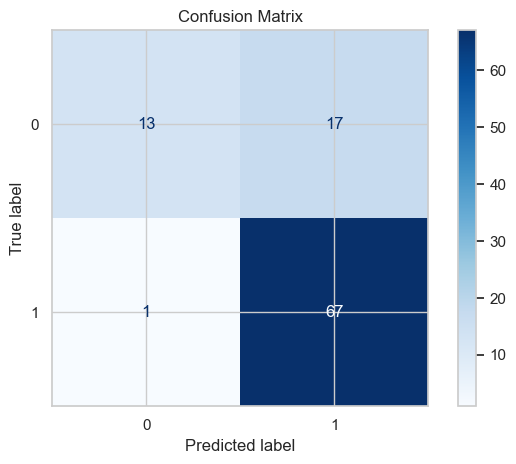

In [138]:
prediction_report(
    svc,
    X_val, 
    y_val
)

In [139]:
y_val_prob_svc = svc.predict_proba(X_val)[:, 1]

svc_auc = roc_auc_score(
    y_val,
    y_val_prob_svc
)

print(f"SVC Validation ROC-AUC: {svc_auc:.4f}")

SVC Validation ROC-AUC: 0.7505


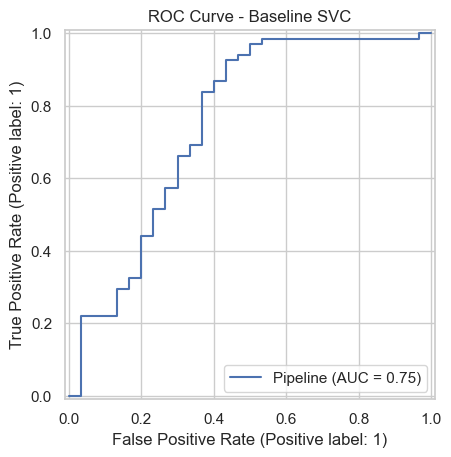

In [140]:
RocCurveDisplay.from_estimator(
    svc,
    X_val,
    y_val
)

plt.title('ROC Curve - Baseline SVC')
plt.show()

### SVC Hyperparameter Tuning

Hyperparameter tuning is performed using stratified 5-fold cross-validation on the training data.

The regularization parameter `C`, kernel type, and kernel coefficient `gamma` are explored to identify a better-performing SVC configuration. The F1-score is used as the optimization metric.

In [141]:
param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__kernel': ['linear', 'rbf'],
    'svc__gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

In [142]:
best_svc = model_tuning(
    svc,
    X_train,
    y_train,
    param_grid
)

Best parameters: {'svc__C': 100, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Best CV F1-score: 0.8871


              precision    recall  f1-score   support

           0       0.71      0.50      0.59        30
           1       0.81      0.91      0.86        68

    accuracy                           0.79        98
   macro avg       0.76      0.71      0.72        98
weighted avg       0.78      0.79      0.77        98



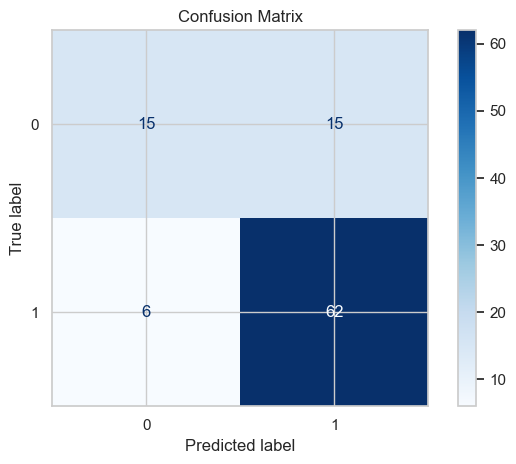

In [143]:
prediction_report(
    best_svc,
    X_val,
    y_val
)

In [144]:
y_val_prob_svc_tuned = best_svc.predict_proba(X_val)[:, 1]

tuned_svc_auc = roc_auc_score(
    y_val,
    y_val_prob_svc_tuned
)

print(f"Tuned SVC Validation ROC-AUC: {tuned_svc_auc:.4f}")

Tuned SVC Validation ROC-AUC: 0.7505


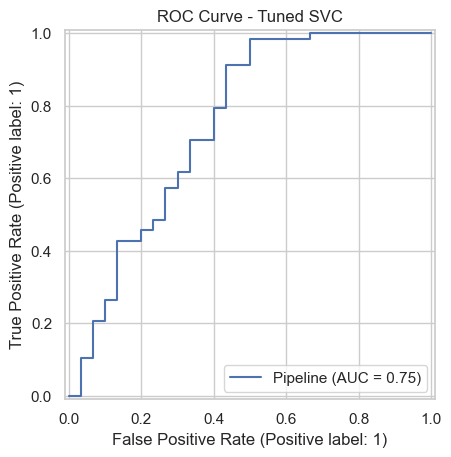

In [145]:
RocCurveDisplay.from_estimator(
    best_svc,
    X_val,
    y_val
)

plt.title('ROC Curve - Tuned SVC')
plt.show()

### SVC Results

The baseline SVC achieved a validation accuracy of 0.82 and a ROC-AUC of 0.7505.

Hyperparameter tuning using stratified 5-fold cross-validation selected an RBF kernel with `C = 100` and `gamma = 0.01`, achieving a best cross-validation F1-score of 0.8871.

On the validation set, the tuned SVC increased recall for class 0 from 0.43 to 0.50. However, overall accuracy decreased from 0.82 to 0.79, recall for class 1 decreased from 0.99 to 0.91, and ROC-AUC remained unchanged at 0.7505.

Therefore, the baseline SVC is retained as the preferred SVC configuration for subsequent model comparison.

## 3. Decision Tree Classifier

A Decision Tree Classifier is evaluated as the next classification model.

Decision trees classify observations by recursively splitting the feature space according to rules that improve class separation. Unlike Logistic Regression and SVC, decision trees can capture nonlinear relationships and interactions between features.

A baseline Decision Tree model is first evaluated before hyperparameter tuning.

In [146]:
dt = make_pipeline(
    preprocessor,
    DecisionTreeClassifier(
        random_state=42
    )
)

dt.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('decisiontreeclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('pipeline-1', ...), ('pipeline-2', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the out

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       119
           1       1.00      1.00      1.00       269

    accuracy                           1.00       388
   macro avg       1.00      1.00      1.00       388
weighted avg       1.00      1.00      1.00       388



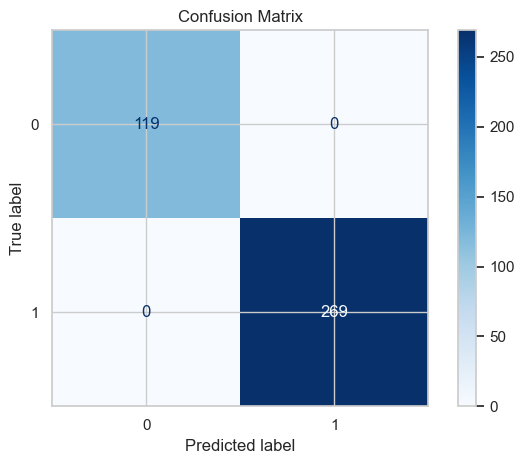

In [147]:
prediction_report(
    dt,
    X_train,
    y_train
)

              precision    recall  f1-score   support

           0       0.57      0.67      0.62        30
           1       0.84      0.78      0.81        68

    accuracy                           0.74        98
   macro avg       0.71      0.72      0.71        98
weighted avg       0.76      0.74      0.75        98



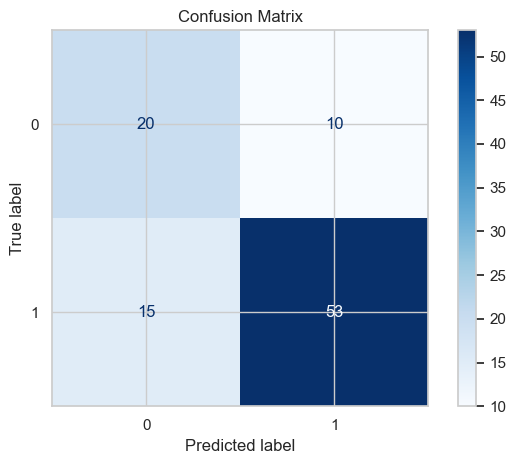

In [148]:
prediction_report(
    dt,
    X_val,
    y_val
)

In [149]:
y_val_prob_dt = dt.predict_proba(X_val)[:, 1]

dt_auc = roc_auc_score(
    y_val,
    y_val_prob_dt
)

print(f"Decision Tree Validation ROC-AUC: {dt_auc:.4f}")

Decision Tree Validation ROC-AUC: 0.7230


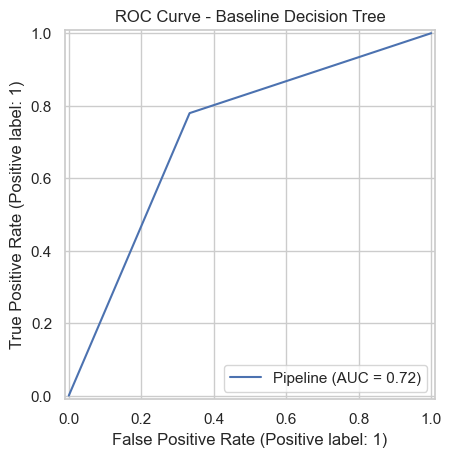

In [150]:
RocCurveDisplay.from_estimator(
    dt,
    X_val,
    y_val
)

plt.title('ROC Curve - Baseline Decision Tree')
plt.show()

### Decision Tree Hyperparameter Tuning

The baseline Decision Tree perfectly classified the training observations but showed substantially lower performance on the validation set, indicating clear overfitting.

Hyperparameter tuning is therefore performed using stratified 5-fold cross-validation to control tree complexity and improve generalization. Parameters related to tree depth, node splitting, and minimum leaf size are explored.

In [151]:
param_grid = {
    'decisiontreeclassifier__max_depth': [2, 3, 4, 5, 6, 8, 10, None],
    'decisiontreeclassifier__min_samples_split': [2, 5, 10, 20],
    'decisiontreeclassifier__min_samples_leaf': [1, 2, 5, 10],
    'decisiontreeclassifier__criterion': ['gini', 'entropy']
}

best_dt = model_tuning(
    dt,
    X_train,
    y_train,
    param_grid
)

Best parameters: {'decisiontreeclassifier__criterion': 'gini', 'decisiontreeclassifier__max_depth': 2, 'decisiontreeclassifier__min_samples_leaf': 1, 'decisiontreeclassifier__min_samples_split': 2}
Best CV F1-score: 0.8820


              precision    recall  f1-score   support

           0       0.93      0.47      0.62        30
           1       0.81      0.99      0.89        68

    accuracy                           0.83        98
   macro avg       0.87      0.73      0.75        98
weighted avg       0.85      0.83      0.81        98



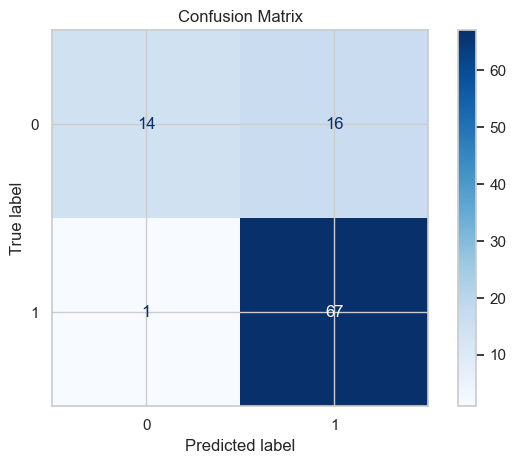

In [152]:
prediction_report(
    best_dt,
    X_val,
    y_val
)

In [153]:
y_val_prob_dt_tuned = best_dt.predict_proba(X_val)[:, 1]

tuned_dt_auc = roc_auc_score(
    y_val,
    y_val_prob_dt_tuned
)

print(f"Tuned Decision Tree Validation ROC-AUC: {tuned_dt_auc:.4f}")

Tuned Decision Tree Validation ROC-AUC: 0.7047


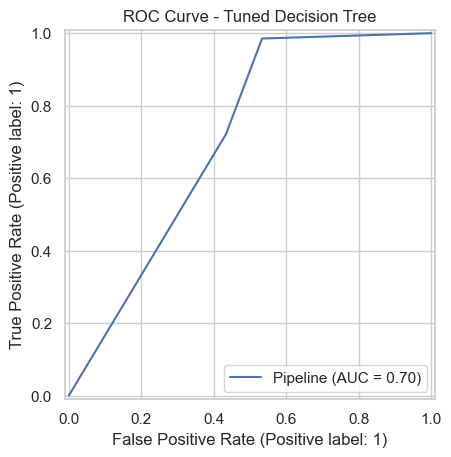

In [154]:
RocCurveDisplay.from_estimator(
    best_dt,
    X_val,
    y_val
)

plt.title('ROC Curve - Tuned Decision Tree')
plt.show()

### Decision Tree Results

The baseline Decision Tree perfectly classified the training data, indicating substantial overfitting.

Hyperparameter tuning using stratified 5-fold cross-validation selected a shallow tree with `max_depth = 2`, `criterion = 'gini'`, `min_samples_leaf = 1`, and `min_samples_split = 2`. The best cross-validation F1-score was 0.8820.

The tuned model achieved approximately 0.83 validation accuracy. It correctly identified 67 of 68 approved applications, but only 14 of 30 rejected applications.

Although limiting tree complexity addressed the severe overfitting observed in the baseline model, the validation ROC-AUC decreased from 0.7230 to 0.7047. Therefore, the tuned Decision Tree does not currently outperform the stronger candidate models.

## 4. K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) is evaluated as another classification model.

KNN classifies an observation based on the classes of its nearest neighboring observations. Because KNN is sensitive to feature scales, numerical features are standardized through the preprocessing pipeline before model training.

A baseline KNN model is first evaluated using the default hyperparameters before hyperparameter tuning.

In [155]:
knn = make_pipeline(
    preprocessor,
    KNeighborsClassifier()
)

In [156]:
knn.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('pipeline-1', ...), ('pipeline-2', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the outpu

              precision    recall  f1-score   support

           0       0.89      0.55      0.68       119
           1       0.83      0.97      0.90       269

    accuracy                           0.84       388
   macro avg       0.86      0.76      0.79       388
weighted avg       0.85      0.84      0.83       388



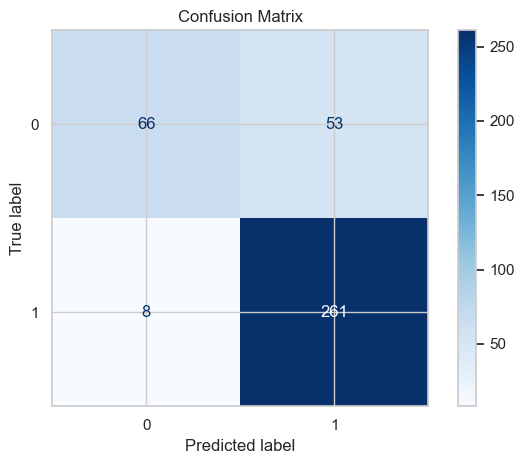

In [157]:
prediction_report(
    knn,
    X_train,
    y_train
)

              precision    recall  f1-score   support

           0       0.88      0.50      0.64        30
           1       0.81      0.97      0.89        68

    accuracy                           0.83        98
   macro avg       0.85      0.74      0.76        98
weighted avg       0.84      0.83      0.81        98



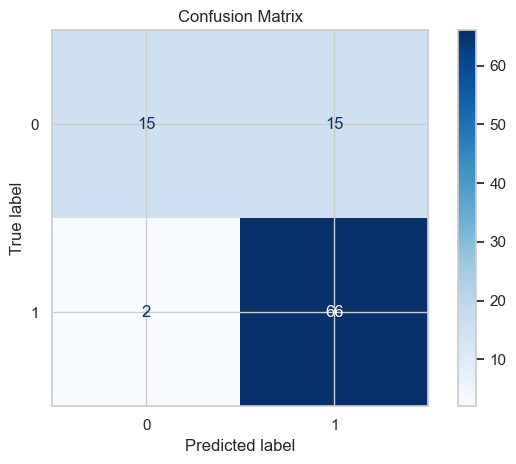

In [158]:
prediction_report(
    knn,
    X_val,
    y_val
)

In [159]:
y_val_prob_knn = knn.predict_proba(X_val)[:, 1]

knn_auc = roc_auc_score(
    y_val,
    y_val_prob_knn
)

print(f"KNN Validation ROC-AUC: {knn_auc:.4f}")

KNN Validation ROC-AUC: 0.7502


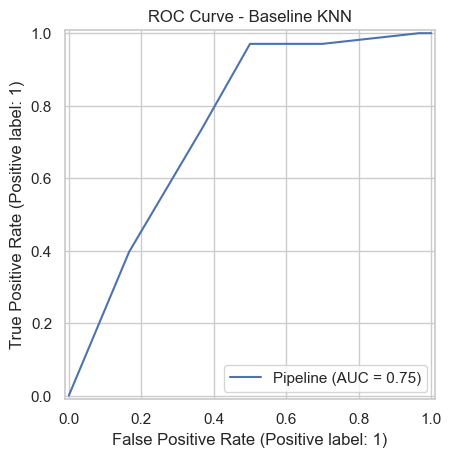

In [160]:
RocCurveDisplay.from_estimator(
    knn,
    X_val,
    y_val
)

plt.title('ROC Curve - Baseline KNN')
plt.show()

### KNN Hyperparameter Tuning

Hyperparameter tuning is performed using stratified 5-fold cross-validation on the training data.

The number of neighbors (`n_neighbors`), neighbor weighting strategy (`weights`), and distance metric parameter (`p`) are explored. The F1-score is used as the optimization metric.

In [161]:
param_grid = {
    'kneighborsclassifier__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'kneighborsclassifier__weights': ['uniform', 'distance'],
    'kneighborsclassifier__p': [1, 2]
}

best_knn = model_tuning(
    knn,
    X_train,
    y_train,
    param_grid
)

Best parameters: {'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__p': 1, 'kneighborsclassifier__weights': 'distance'}
Best CV F1-score: 0.8602


              precision    recall  f1-score   support

           0       0.93      0.43      0.59        30
           1       0.80      0.99      0.88        68

    accuracy                           0.82        98
   macro avg       0.86      0.71      0.74        98
weighted avg       0.84      0.82      0.79        98



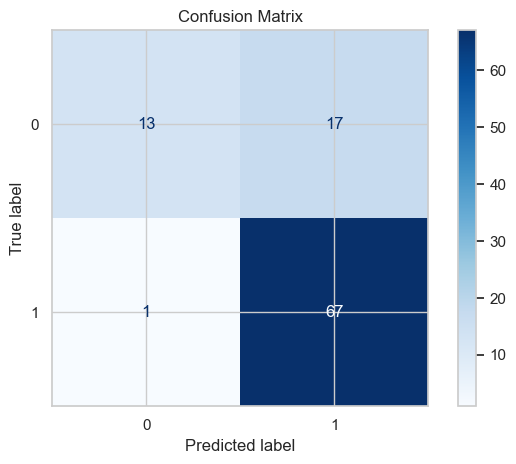

In [162]:
prediction_report(
    best_knn,
    X_val,
    y_val
)

In [163]:
y_val_prob_knn_tuned = best_knn.predict_proba(X_val)[:, 1]

tuned_knn_auc = roc_auc_score(
    y_val,
    y_val_prob_knn_tuned
)

print(f"Tuned KNN Validation ROC-AUC: {tuned_knn_auc:.4f}")

Tuned KNN Validation ROC-AUC: 0.7588


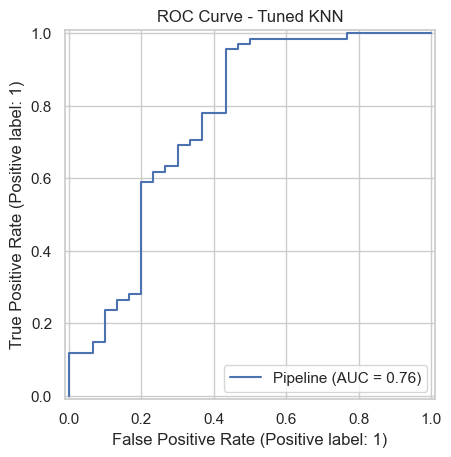

In [164]:
RocCurveDisplay.from_estimator(
    best_knn,
    X_val,
    y_val
)

plt.title('ROC Curve - Tuned KNN')
plt.show()

### KNN Results

The baseline KNN achieved a validation ROC-AUC of 0.7502.

Hyperparameter tuning using stratified 5-fold cross-validation selected `n_neighbors = 15`, `weights = 'distance'`, and `p = 1`, with a best cross-validation F1-score of 0.8602.

The tuned KNN achieved a validation ROC-AUC of 0.7588, representing a modest improvement over the baseline model. However, the validation accuracy decreased slightly to approximately 0.82.

The tuned model correctly identified 67 of 68 approved applications, while correctly identifying 13 of 30 rejected applications. This indicates strong performance for class 1 but weaker sensitivity to class 0.

The tuned KNN is retained as the preferred KNN configuration for subsequent model comparison.

## 5. Random Forest Classifier

Random Forest is evaluated as an ensemble-based classification model.

It combines multiple decision trees and aggregates their predictions, which can improve generalization and reduce the overfitting commonly observed with a single Decision Tree.

A baseline Random Forest model is first evaluated before hyperparameter tuning.

In [165]:
rf = make_pipeline(
    preprocessor,
    RandomForestClassifier(
        random_state=42
    )
)

In [166]:
rf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('randomforestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('pipeline-1', ...), ('pipeline-2', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the out

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       119
           1       1.00      1.00      1.00       269

    accuracy                           1.00       388
   macro avg       1.00      1.00      1.00       388
weighted avg       1.00      1.00      1.00       388



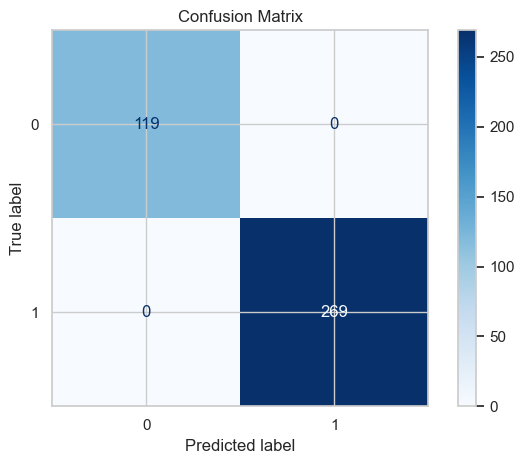

In [167]:
prediction_report(
    rf,
    X_train,
    y_train
)

              precision    recall  f1-score   support

           0       0.76      0.53      0.63        30
           1       0.82      0.93      0.87        68

    accuracy                           0.81        98
   macro avg       0.79      0.73      0.75        98
weighted avg       0.80      0.81      0.80        98



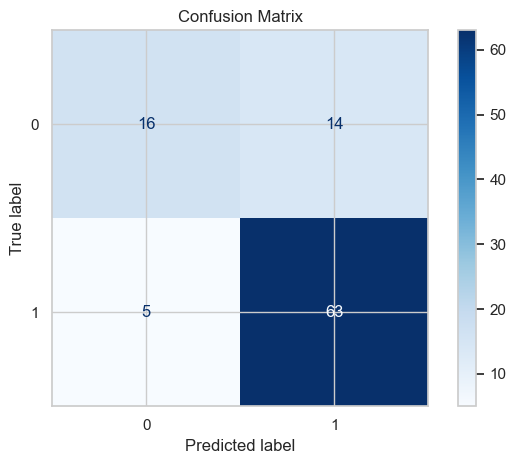

In [168]:
prediction_report(
    rf,
    X_val,
    y_val
)

In [169]:
y_val_prob_rf = rf.predict_proba(X_val)[:, 1]

rf_auc = roc_auc_score(
    y_val,
    y_val_prob_rf
)

print(f"Random Forest Validation ROC-AUC: {rf_auc:.4f}")

Random Forest Validation ROC-AUC: 0.7397


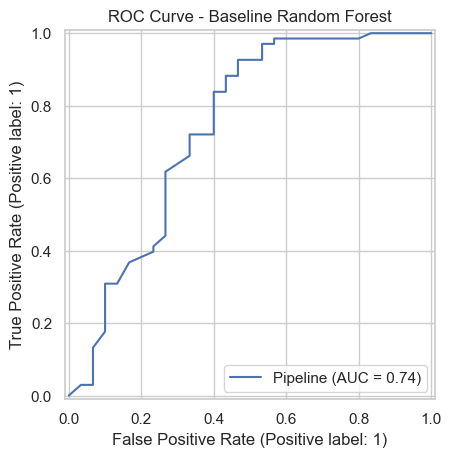

In [170]:
RocCurveDisplay.from_estimator(
    rf,
    X_val,
    y_val
)

plt.title('ROC Curve - Baseline Random Forest')
plt.show()

### Random Forest Hyperparameter Tuning

Hyperparameter tuning is performed using stratified 5-fold cross-validation on the training data.

The number of trees, maximum tree depth, minimum number of samples required to split a node, minimum leaf size, and number of features considered at each split are explored. The F1-score is used as the optimization metric.

In [171]:
param_grid = {
    'randomforestclassifier__n_estimators': [100, 200, 300],
    'randomforestclassifier__max_depth': [None, 3, 5, 7, 10],
    'randomforestclassifier__min_samples_split': [2, 5, 10],
    'randomforestclassifier__min_samples_leaf': [1, 2, 4],
    'randomforestclassifier__max_features': ['sqrt', 'log2']
}

In [172]:
best_rf = model_tuning(
    rf,
    X_train,
    y_train,
    param_grid
)

KeyboardInterrupt: 

              precision    recall  f1-score   support

           0       0.93      0.47      0.62        30
           1       0.81      0.99      0.89        68

    accuracy                           0.83        98
   macro avg       0.87      0.73      0.75        98
weighted avg       0.85      0.83      0.81        98



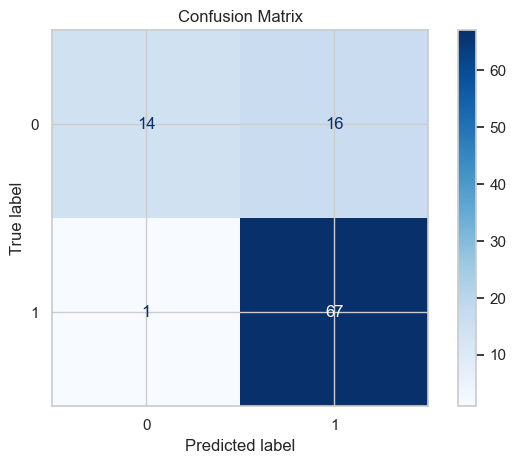

In [ ]:
prediction_report(
    best_rf,
    X_val,
    y_val
)

In [ ]:
y_val_prob_rf_tuned = best_rf.predict_proba(X_val)[:, 1]

tuned_rf_auc = roc_auc_score(
    y_val,
    y_val_prob_rf_tuned
)

print(f"Tuned Random Forest Validation ROC-AUC: {tuned_rf_auc:.4f}")

Tuned Random Forest Validation ROC-AUC: 0.7186


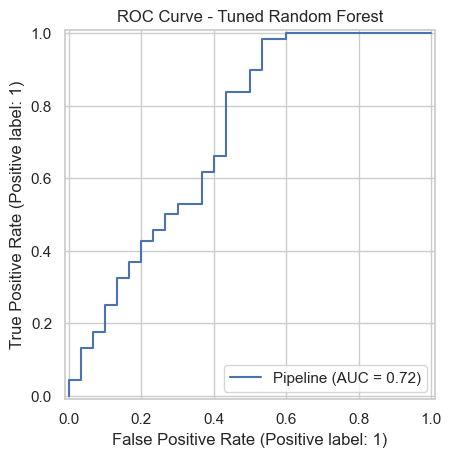

In [ ]:
RocCurveDisplay.from_estimator(
    best_rf,
    X_val,
    y_val
)

plt.title('ROC Curve - Tuned Random Forest')
plt.show()

### Random Forest Results

The baseline Random Forest achieved a validation ROC-AUC of 0.7397.

Hyperparameter tuning using stratified 5-fold cross-validation selected `max_depth = 3`, `max_features = 'sqrt'`, `min_samples_leaf = 2`, `min_samples_split = 5`, and `n_estimators = 200`, with a best cross-validation F1-score of 0.8820.

The tuned model achieved a slightly higher validation accuracy of approximately 0.83 and very high recall for class 1. However, recall for class 0 decreased, and ROC-AUC declined from 0.7397 to 0.7186.

Therefore, the baseline Random Forest is retained as the preferred Random Forest configuration for subsequent model comparison.

## 6. Model Comparison

After evaluating and tuning the candidate classification algorithms, the preferred version of each model is compared using validation-set performance.

The test set remains untouched during this stage. Model selection is based primarily on ROC-AUC while also considering accuracy and class-specific performance.

In [173]:
models = {
    'Logistic Regression': best_log_reg,
    'SVC': svc,
    'KNN': best_knn,
    'Decision Tree': best_dt,
    'Random Forest': rf
}

In [176]:
comparison_results = []

for name, model in models.items():
    
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]
    
    comparison_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred),
        'Recall': recall_score(y_val, y_pred),
        'F1-score': f1_score(y_val, y_pred),
        'ROC-AUC': roc_auc_score(y_val, y_prob)
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,KNN,0.8163,0.7976,0.9853,0.8816,0.7588
1,SVC,0.8163,0.7976,0.9853,0.8816,0.7505
2,Random Forest,0.8061,0.8182,0.9265,0.8690,0.7397
3,Logistic Regression,0.8265,0.8072,0.9853,0.8874,0.7309
4,Decision Tree,0.8265,0.8072,0.9853,0.8874,0.7047


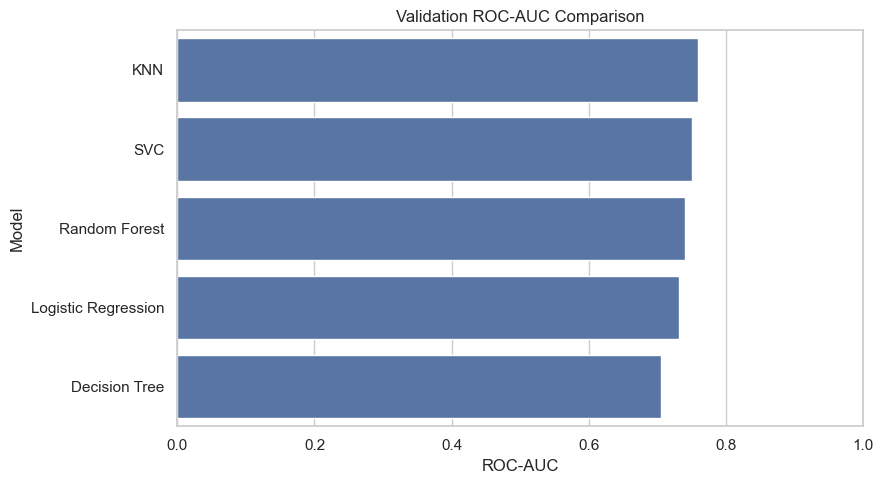

In [175]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_df,
    x='ROC-AUC',
    y='Model'
)

plt.title('Validation ROC-AUC Comparison')
plt.xlabel('ROC-AUC')
plt.ylabel('Model')
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

### Final Model Selection

Based on the validation-set comparison, the tuned KNN model achieved the highest ROC-AUC of 0.7588 among the evaluated classifiers.

Although Logistic Regression and Decision Tree achieved slightly higher validation accuracy and F1-score, KNN provided the strongest overall discrimination according to the primary selection metric, ROC-AUC.

The tuned KNN also achieved a recall of 0.9853 and an F1-score of 0.8816 for the positive class.

Therefore, the tuned KNN model is selected as the final model for evaluation on the previously untouched test set.

In [177]:
final_knn = make_pipeline(
    preprocessor,
    KNeighborsClassifier(
        n_neighbors=15,
        weights='distance',
        p=1
    )
)

final_knn.fit(X_train_val, y_train_val)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('pipeline-1', ...), ('pipeline-2', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the outpu

              precision    recall  f1-score   support

           0       0.62      0.26      0.37        38
           1       0.74      0.93      0.82        84

    accuracy                           0.72       122
   macro avg       0.68      0.60      0.60       122
weighted avg       0.70      0.72      0.68       122



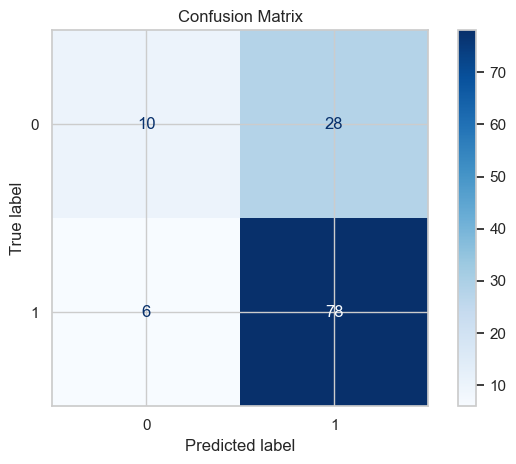

In [178]:
prediction_report(
    final_knn,
    X_test,
    y_test
)

In [179]:
y_test_prob = final_knn.predict_proba(X_test)[:, 1]

final_test_auc = roc_auc_score(
    y_test,
    y_test_prob
)

print(f"Final KNN Test ROC-AUC: {final_test_auc:.4f}")

Final KNN Test ROC-AUC: 0.7249


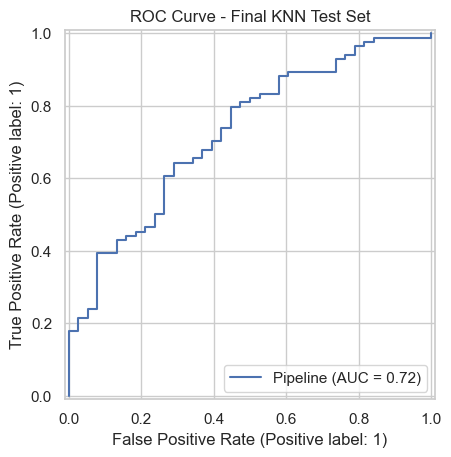

In [180]:
RocCurveDisplay.from_estimator(
    final_knn,
    X_test,
    y_test
)

plt.title('ROC Curve - Final KNN Test Set')
plt.show()

## Final Model Evaluation

The tuned KNN model was selected based on validation-set performance and was retrained using the combined training and validation data before final evaluation on the previously untouched test set.

The final model used:

- `n_neighbors = 15`
- `weights = 'distance'`
- `p = 1`

On the test set, the model achieved a ROC-AUC of **0.7249** and an accuracy of approximately **0.7213**.

The confusion matrix showed:

- 10 correctly classified rejected applications.
- 28 rejected applications incorrectly classified as approved.
- 6 approved applications incorrectly classified as rejected.
- 78 correctly classified approved applications.

The model demonstrated high sensitivity to approved applications, correctly identifying approximately 92.9% of class 1 observations. However, its ability to identify rejected applications was considerably weaker, with a class 0 recall of approximately 26.3%.

The decrease in ROC-AUC from 0.7588 on the validation set to 0.7249 on the test set indicates somewhat weaker performance on unseen data, although the model retained moderate discriminatory ability.

In [182]:
y_test_pred = final_knn.predict(X_test)

print("Final KNN Test Classification Report:\n")
print(classification_report(y_test, y_test_pred))

Final KNN Test Classification Report:

              precision    recall  f1-score   support

           0       0.62      0.26      0.37        38
           1       0.74      0.93      0.82        84

    accuracy                           0.72       122
   macro avg       0.68      0.60      0.60       122
weighted avg       0.70      0.72      0.68       122



### Final Test Performance Interpretation

The final KNN model achieved an accuracy of 0.72 and a ROC-AUC of 0.7249 on the previously unseen test set.

Performance differed considerably between the two target classes. For approved applications (class 1), the model achieved a recall of 0.93 and an F1-score of 0.82, indicating that most historically approved applications were correctly identified.

However, performance for rejected applications (class 0) was substantially weaker, with a recall of 0.26 and an F1-score of 0.37. This indicates that many historically rejected applications were incorrectly classified as approved.

Overall, the final model demonstrates moderate discriminatory performance but a clear tendency toward predicting the majority approval class. This limitation should be considered when interpreting the model's predictions.

## Model Saving

The final trained KNN pipeline is saved using `joblib`.

The saved Scikit-learn pipeline includes missing-value imputation, numerical feature scaling, categorical one-hot encoding, and the trained KNN classifier.

Some transformations used during data preparation, including the `Credit_History` mapping and the `log1p` transformations applied to `ApplicantIncome` and `LoanAmount`, were performed before the Scikit-learn pipeline. Therefore, new raw observations must undergo these same transformations before being passed to the saved model.

The `CoapplicantIncome` outlier filtering step was applied only during training-data preparation and was not used to remove observations from the external prediction dataset.

In [183]:
import joblib
joblib.dump(
    final_knn,
    'home_loan_approval_knn_pipeline.pkl'
)

print("Final model saved successfully.")

Final model saved successfully.


In [184]:
loaded_model = joblib.load(
    'home_loan_approval_knn_pipeline.pkl'
)

loaded_predictions = loaded_model.predict(X_test)

print(
    "Predictions identical:",
    np.array_equal(y_test_pred, loaded_predictions)
)

Predictions identical: True


## Predictions on External Test Data

The final trained KNN pipeline is applied to the external test dataset.

Because this dataset does not contain the `Loan_Status` target variable, it cannot be used to calculate classification performance metrics. Instead, the model generates predicted loan-status classes and approval probabilities for each application.

In [185]:
test_external = pd.read_csv('loan_sanction_test.csv')

print("External test shape:", test_external.shape)
test_external.head()

External test shape: (367, 12)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban


In [186]:
loan_ids = test_external['Loan_ID'].copy()

X_external = test_external.drop(columns=['Loan_ID']).copy()

In [187]:
X_external['Credit_History'] = X_external['Credit_History'].map({
    1: 'Yes',
    0: 'No'
})

for col in ['ApplicantIncome', 'LoanAmount']:
    X_external[col] = np.log1p(X_external[col])

In [188]:
external_predictions = loaded_model.predict(X_external)

external_probabilities = loaded_model.predict_proba(X_external)[:, 1]

In [189]:
predicted_status = np.where(
    external_predictions == 1,
    'Y',
    'N'
)

In [190]:
external_results = pd.DataFrame({
    'Loan_ID': loan_ids,
    'Predicted_Loan_Status': predicted_status,
    'Approval_Probability': external_probabilities
})

external_results.head(10)

,Loan_ID,Predicted_Loan_Status,Approval_Probability
0,LP001015,Y,0.948109
1,LP001022,Y,0.848013
2,LP001031,Y,0.723623
3,LP001035,Y,0.905987
4,LP001051,Y,0.538503
5,LP001054,Y,0.862754
6,LP001055,Y,0.706617
7,LP001056,N,0.367573
8,LP001059,Y,0.879580
9,LP001067,Y,0.965380


In [191]:
print("Number of predictions:", len(external_results))

print("\nPredicted class distribution:")
print(external_results['Predicted_Loan_Status'].value_counts())

external_results.head()

Number of predictions: 367

Predicted class distribution:
Predicted_Loan_Status
Y    313
N     54
Name: count, dtype: int64


,Loan_ID,Predicted_Loan_Status,Approval_Probability
0,LP001015,Y,0.948109
1,LP001022,Y,0.848013
2,LP001031,Y,0.723623
3,LP001035,Y,0.905987
4,LP001051,Y,0.538503


In [192]:
external_results.to_csv(
    'loan_approval_predictions.csv',
    index=False
)

print("External predictions saved successfully.")

External predictions saved successfully.


In [193]:
pd.read_csv('loan_approval_predictions.csv').head()

,Loan_ID,Predicted_Loan_Status,Approval_Probability
0,LP001015,Y,0.948109
1,LP001022,Y,0.848013
2,LP001031,Y,0.723623
3,LP001035,Y,0.905987
4,LP001051,Y,0.538503


# Conclusion

This project developed and evaluated multiple machine learning classification models for predicting historical home loan approval status.

The workflow included data exploration, missing-value analysis, outlier and skewness handling, feature preprocessing, stratified data splitting, model training, hyperparameter tuning, validation-based model comparison, and final evaluation on an untouched test set.

Five classification algorithms were evaluated:

- Logistic Regression
- Support Vector Classifier (SVC)
- Decision Tree
- K-Nearest Neighbors (KNN)
- Random Forest

Based on validation ROC-AUC, the tuned KNN model was selected as the final model, achieving a validation ROC-AUC of **0.7588**.

The selected KNN model used:

- `n_neighbors = 15`
- `weights = 'distance'`
- `p = 1`

After model selection, the final pipeline was retrained using the combined training and validation data and evaluated once on the previously untouched test set.

On the test set, the final model achieved:

- **Accuracy: 0.72**
- **ROC-AUC: 0.7249**
- **Precision for class 1: 0.74**
- **Recall for class 1: 0.93**
- **F1-score for class 1: 0.82**
- **Precision for class 0: 0.62**
- **Recall for class 0: 0.26**
- **F1-score for class 0: 0.37**

The final model demonstrated strong sensitivity to historically approved applications but substantially weaker performance for historically rejected applications. This indicates a tendency toward predicting the majority approval class.

Therefore, while the model demonstrates moderate discriminatory ability, its class-specific limitations should be considered before any practical use. Future work could explore class-imbalance strategies, decision-threshold optimization, additional feature engineering, and larger datasets to improve performance, particularly for class 0.

Finally, the complete preprocessing and KNN model pipeline was saved for reproducible future predictions, and predictions were generated for the external test dataset.